In [43]:
import pandas as pd
import sklearn
import numpy as np
import matplotlib.pyplot as plt

In [3]:
x = np.random.random((500,4))
df = pd.DataFrame(data=x)
df

,0,1,2,3
0,0.481318,0.494717,0.700000,0.154715
1,0.955630,0.254045,0.916710,0.632876
2,0.470518,0.753840,0.447211,0.691057
3,0.206291,0.420603,0.227501,0.511309
4,0.001585,0.460082,0.567613,0.961408
...,...,...,...,...
495,0.194237,0.557157,0.607434,0.703519
496,0.846346,0.149430,0.138331,0.324493
497,0.596065,0.845899,0.963853,0.802682
498,0.916489,0.177537,0.098246,0.466575


In [7]:
t = []
for i in range(500):
  if i>249:
    t.append(0)
  else:
    t.append(1)

In [8]:
t

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [9]:
df['traget'] = t
df

,0,1,2,3,traget
0,0.481318,0.494717,0.700000,0.154715,1
1,0.955630,0.254045,0.916710,0.632876,1
2,0.470518,0.753840,0.447211,0.691057,1
3,0.206291,0.420603,0.227501,0.511309,1
4,0.001585,0.460082,0.567613,0.961408,1
...,...,...,...,...,...
495,0.194237,0.557157,0.607434,0.703519,0
496,0.846346,0.149430,0.138331,0.324493,0
497,0.596065,0.845899,0.963853,0.802682,0
498,0.916489,0.177537,0.098246,0.466575,0


In [10]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [13]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

ABC = AdaBoostClassifier(n_estimators=50, estimator=nb,learning_rate=1)
ABC.fit(X_train,y_train)

AdaBoostClassifier(estimator=GaussianNB(), learning_rate=1)

In [22]:
even_results = []
odd_results = []

for i in range(1, 20):
    ABC = AdaBoostClassifier(n_estimators=i, estimator=nb, learning_rate=1)
    ABC.fit(X_train, y_train)
    score = ABC.score(X_test, y_test)

    if i % 2 == 0:
        even_results.append((i, score))
    else:
        odd_results.append((i, score))

print(" EVEN ESTIMATORS ")
for est, score in even_results:
    print(f"n_estimators = {est}: Score = {score}")

print("ODD ESTIMATORS ")
for est, score in odd_results:
    print(f"n_estimators = {est}: Score = {score}")

 EVEN ESTIMATORS 
n_estimators = 2: Score = 0.49
n_estimators = 4: Score = 0.49
n_estimators = 6: Score = 0.49
n_estimators = 8: Score = 0.49
n_estimators = 10: Score = 0.49
n_estimators = 12: Score = 0.49
n_estimators = 14: Score = 0.49
n_estimators = 16: Score = 0.49
n_estimators = 18: Score = 0.49
ODD ESTIMATORS 
n_estimators = 1: Score = 0.49
n_estimators = 3: Score = 0.49
n_estimators = 5: Score = 0.49
n_estimators = 7: Score = 0.49
n_estimators = 9: Score = 0.49
n_estimators = 11: Score = 0.49
n_estimators = 13: Score = 0.49
n_estimators = 15: Score = 0.49
n_estimators = 17: Score = 0.49
n_estimators = 19: Score = 0.49


RESULTS FOR LEARNING RATE: 0.2
n_estimators = 5: Score = 0.49
n_estimators = 20: Score = 0.49
n_estimators = 30: Score = 0.49
n_estimators = 40: Score = 0.49
n_estimators = 50: Score = 0.49


RESULTS FOR LEARNING RATE: 0.3
n_estimators = 5: Score = 0.49
n_estimators = 20: Score = 0.51
n_estimators = 30: Score = 0.51
n_estimators = 40: Score = 0.51
n_estimators = 50: Score = 0.51


RESULTS FOR LEARNING RATE: 0.5
n_estimators = 5: Score = 0.52
n_estimators = 20: Score = 0.54
n_estimators = 30: Score = 0.54
n_estimators = 40: Score = 0.54
n_estimators = 50: Score = 0.54


RESULTS FOR LEARNING RATE: 0.7
n_estimators = 5: Score = 0.51
n_estimators = 20: Score = 0.51
n_estimators = 30: Score = 0.51
n_estimators = 40: Score = 0.51
n_estimators = 50: Score = 0.51


RESULTS FOR LEARNING RATE: 0.9
n_estimators = 5: Score = 0.49
n_estimators = 20: Score = 0.49
n_estimators = 30: Score = 0.49
n_estimators = 40: Score = 0.49
n_estimators = 50: Score = 0.49




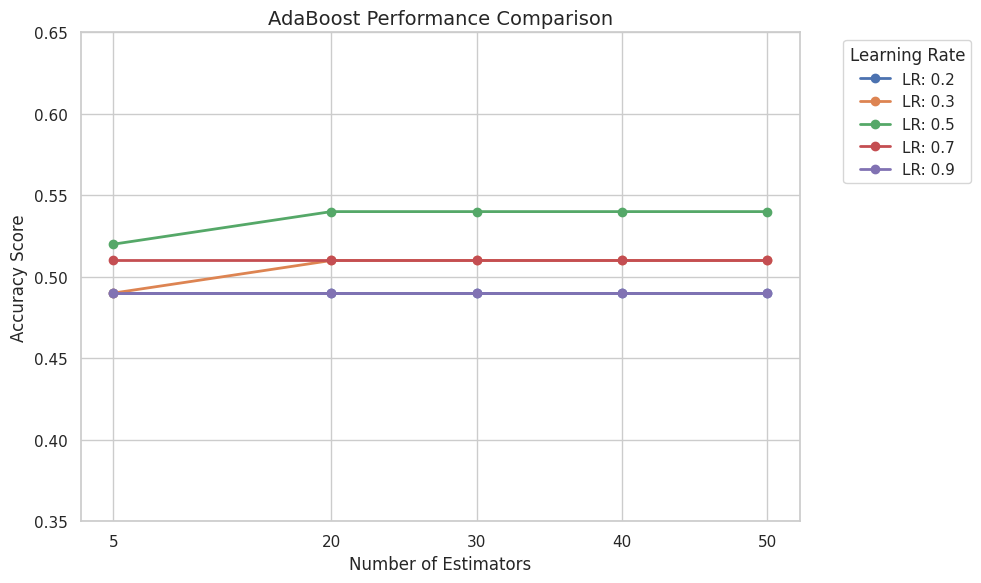

In [44]:
learning_rates = [0.2, 0.3, 0.5, 0.7, 0.9]
estimators_to_test = [5, 20, 30, 40, 50]
plot_data = []

for lr in learning_rates:
    print(f"RESULTS FOR LEARNING RATE: {lr}")
    for n_est in estimators_to_test:
        ABC = AdaBoostClassifier(n_estimators=n_est, estimator=nb, learning_rate=lr)
        ABC.fit(X_train, y_train)
        score = ABC.score(X_test, y_test)
        print(f"n_estimators = {n_est}: Score = {score}")
        plot_data.append({
            'Learning Rate': lr,
            'Number of Estimators': n_est,
            'Accuracy Score': score
        })
    print("\n")

results_df = pd.DataFrame(plot_data)
plt.figure(figsize=(10, 6))
for lr, group in results_df.groupby('Learning Rate'):
    plt.plot(
        group['Number of Estimators'],
        group['Accuracy Score'],
        marker='o',
        linewidth=2,
        label=f'LR: {lr}'
    )
plt.title('AdaBoost Performance Comparison', fontsize=14)
plt.xlabel('Number of Estimators', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.xticks(estimators_to_test)
plt.ylim(0.35, 0.65)
plt.legend(title='Learning Rate', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()